In [1]:
# ============================================================
# BLOCK 1: IMPORTS + REPRODUCIBILITY
# ------------------------------------------------------------
# This block sets up:
# - All required libraries
# - Deterministic behavior for reproducibility
# ============================================================

import os
import random
import numpy as np
import pandas as pd
from PIL import Image
!pip install torchinfo

# ----------------------------
# PyTorch Core
# ----------------------------
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchinfo import summary

# ----------------------------
# Torch Utilities
# ----------------------------
from torch.utils.data import DataLoader, Dataset, Subset

# ----------------------------
# TorchVision
# ----------------------------
import torchvision.models as models
import torchvision.transforms as transforms
import torchvision.datasets as datasets

# ----------------------------
# Metrics & Tools
# ----------------------------
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.model_selection import StratifiedShuffleSplit

# ----------------------------
# Visualization & Progress
# ----------------------------
import matplotlib.pyplot as plt
from tqdm import tqdm
from tqdm.notebook import tqdm
import random
# ============================================================
# SEED SETTING (VERY IMPORTANT FOR REPRODUCIBILITY)
# ============================================================

SEED = 1234

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)

# Ensures deterministic behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [2]:
# ============================================================
# BLOCK 2: COMBINED BREAKHIS DATASET (40X + 100X + 200X + 400X)
# ------------------------------------------------------------
# This block:
# - Combines all magnifications
# - Performs stratified splitting
# - Creates train/val/test loaders
# ============================================================

import os
import torch
import numpy as np
from PIL import Image
from collections import Counter, defaultdict

from torchvision import transforms
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from sklearn.model_selection import train_test_split

# ============================================================
# TRANSFORMS
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(
        degrees=25,
        translate=(0.25, 0.25),
        scale=(0.75, 1.25)
    ),
    transforms.ToTensor(),

    # Using ImageNet normalization
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# DATASET PATH
# ============================================================

BASE_PATH = '/kaggle/input/datasets/maitygouranga/breakhis-binary-multi/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria'

MAGNIFICATIONS = ['40X', '100X', '200X', '400X']

# ============================================================
# COMBINE ALL MAGNIFICATIONS
# ============================================================

def combine_magnifications_classwise(base_path, magnifications):

    class_to_paths = defaultdict(list)

    print("📂 Combining all magnifications...\n")

    for mag in magnifications:

        mag_path = os.path.join(base_path, mag)

        if not os.path.exists(mag_path):
            print(f"⚠️ Missing folder: {mag_path}")
            continue

        for class_name in os.listdir(mag_path):

            class_path = os.path.join(mag_path, class_name)

            if not os.path.isdir(class_path):
                continue

            for img_file in os.listdir(class_path):

                if img_file.lower().endswith(
                    ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')
                ):

                    img_path = os.path.join(class_path, img_file)

                    class_to_paths[class_name].append(img_path)

        print(f"✅ Processed {mag}")

    class_names = sorted(class_to_paths.keys())

    print("\n📊 Combined Dataset Statistics:\n")

    total_images = 0

    for cls in class_names:

        count = len(class_to_paths[cls])

        total_images += count

        print(f"{cls}: {count}")

    print(f"\nTotal Images: {total_images}")

    return class_to_paths, class_names

# ============================================================
# CREATE COMBINED SAMPLE LIST
# ============================================================

def create_combined_dataset(class_to_paths, class_names):

    all_samples = []

    class_to_idx = {
        cls_name: idx
        for idx, cls_name in enumerate(class_names)
    }

    for class_name, paths in class_to_paths.items():

        label = class_to_idx[class_name]

        for path in paths:

            all_samples.append((path, label))

    return all_samples

# ============================================================
# CUSTOM DATASET
# ============================================================

class CombinedMagnificationDataset(Dataset):

    def __init__(self, samples, transform=None):

        self.samples = samples
        self.transform = transform

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, idx):

        img_path, label = self.samples[idx]

        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

# ============================================================
# COMBINE DATA
# ============================================================

class_to_paths, class_names = combine_magnifications_classwise(
    BASE_PATH,
    MAGNIFICATIONS
)

all_samples = create_combined_dataset(
    class_to_paths,
    class_names
)

# ============================================================
# STRATIFIED SPLITTING
# ------------------------------------------------------------
# Train = 70%
# Val   = 20%
# Test  = 10%
# ============================================================

labels = [label for _, label in all_samples]

indices = np.arange(len(all_samples))

# First split → Train (70%) + Temp (30%)
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Temp labels
temp_labels = [labels[i] for i in temp_idx]

# Split Temp → Val (20%) + Test (10%)
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=1/3,
    stratify=temp_labels,
    random_state=42
)

# ============================================================
# CREATE SPLIT SAMPLE LISTS
# ============================================================

train_samples = [all_samples[i] for i in train_idx]
val_samples = [all_samples[i] for i in val_idx]
test_samples = [all_samples[i] for i in test_idx]

# ============================================================
# CREATE DATASETS
# ============================================================

train_dataset = CombinedMagnificationDataset(
    train_samples,
    transform=train_transform
)

val_dataset = CombinedMagnificationDataset(
    val_samples,
    transform=val_test_transform
)

test_dataset = CombinedMagnificationDataset(
    test_samples,
    transform=val_test_transform
)

# ============================================================
# WEIGHTED RANDOM SAMPLER (TRAIN ONLY)
# ============================================================

train_targets = np.array([label for _, label in train_samples])

class_counts = np.bincount(train_targets)

class_weights = 1.0 / class_counts

sample_weights = class_weights[train_targets]

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

# ============================================================
# CLASS COUNT FUNCTION
# ============================================================

def count_per_class(samples):

    labels = [label for _, label in samples]

    return Counter(labels)

# ============================================================
# PRINT DATASET STATISTICS
# ============================================================

train_class_counts = count_per_class(train_samples)
val_class_counts = count_per_class(val_samples)
test_class_counts = count_per_class(test_samples)

print("\n📂 Classes:")
print(class_names)

print(f"\nTotal images: {len(all_samples)}")
print(f"Training images: {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")
print(f"Test images: {len(test_dataset)}")

print("\nTraining set class counts:")
print(train_class_counts)

print("\nValidation set class counts:")
print(val_class_counts)

print("\nTest set class counts:")
print(test_class_counts)

📂 Combining all magnifications...

✅ Processed 40X
✅ Processed 100X
✅ Processed 200X
✅ Processed 400X

📊 Combined Dataset Statistics:

benign: 2480
malignant: 5429

Total Images: 7909

📂 Classes:
['benign', 'malignant']

Total images: 7909
Training images: 5536
Validation images: 1582
Test images: 791

Training set class counts:
Counter({1: 3800, 0: 1736})

Validation set class counts:
Counter({1: 1086, 0: 496})

Test set class counts:
Counter({1: 543, 0: 248})


In [3]:
# ============================================================
# BLOCK 3: MODIFIED CBAM
# ------------------------------------------------------------
# IMPROVEMENTS OVER STANDARD CBAM:
#
# 1. Added Standard Deviation Pooling
# 2. Dual-path Channel Attention
# 3. Concatenation-based Fusion
# 4. Enhanced Spatial Attention
#
# IMPORTANT:
# Added sigmoid stabilization before feature scaling
# to prevent unstable attention magnitudes.
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# STANDARD DEVIATION POOLING
# ============================================================

class StdPool(nn.Module):

    def forward(self, x):

        return torch.std(x, dim=(2, 3), keepdim=True)


# ============================================================
# SPATIAL STD POOLING
# ============================================================

class SpatialStdPool(nn.Module):

    def forward(self, x):

        return torch.std(x, dim=1, keepdim=True)


# ============================================================
# MODIFIED CHANNEL ATTENTION
# ============================================================

class DualPathConcatChannelAttention(nn.Module):

    def __init__(self, in_channels, reduction=16):

        super().__init__()

        # ----------------------------------------------------
        # Pooling layers
        # ----------------------------------------------------

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.std_pool = StdPool()

        # ----------------------------------------------------
        # Shared MLP
        # ----------------------------------------------------

        self.mlp = nn.Sequential(

            nn.Linear(
                in_channels,
                in_channels // reduction,
                bias=False
            ),

            nn.ReLU(inplace=True),

            nn.Linear(
                in_channels // reduction,
                in_channels,
                bias=False
            )
        )

        # ----------------------------------------------------
        # Activations
        # ----------------------------------------------------

        self.relu = nn.ReLU(inplace=True)

        self.gelu = nn.GELU()

        # ----------------------------------------------------
        # Fusion Conv
        # Compress:
        # 2C → C
        # ----------------------------------------------------

        self.channel_fusion = nn.Conv2d(
            in_channels * 2,
            in_channels,
            kernel_size=1,
            bias=False
        )

    def forward(self, x):

        B, C, H, W = x.shape

        # ====================================================
        # UPPER PATH
        # Avg + Max + ReLU
        # ====================================================

        max_out = self.max_pool(x).view(B, C)

        avg_out_upper = self.avg_pool(x).view(B, C)

        max_out = self.mlp(max_out)

        avg_out_upper = self.mlp(avg_out_upper)

        upper_attention = max_out + avg_out_upper

        upper_attention = self.relu(upper_attention)

        upper_attention = upper_attention.view(B, C, 1, 1)

        # ====================================================
        # LOWER PATH
        # Avg + Std + GELU
        # ====================================================

        avg_out_lower = self.avg_pool(x).view(B, C)

        std_out = self.std_pool(x).view(B, C)

        avg_out_lower = self.mlp(avg_out_lower)

        std_out = self.mlp(std_out)

        lower_attention = avg_out_lower + std_out

        lower_attention = self.gelu(lower_attention)

        lower_attention = lower_attention.view(B, C, 1, 1)

        # ====================================================
        # CONCATENATION
        # ====================================================

        concat_attention = torch.cat(
            [upper_attention, lower_attention],
            dim=1
        )

        # ====================================================
        # CHANNEL FUSION
        # 2C → C
        # ====================================================

        fused_attention = self.channel_fusion(concat_attention)

        # ====================================================
        # IMPORTANT STABILIZATION
        # ----------------------------------------------------
        # Prevents exploding feature scaling
        # ====================================================

        fused_attention = torch.sigmoid(fused_attention)

        # ====================================================
        # APPLY CHANNEL ATTENTION
        # ====================================================

        out = x * fused_attention

        return out


# ============================================================
# MODIFIED SPATIAL ATTENTION
# ============================================================

class ModifiedSpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super().__init__()

        self.std_pool = SpatialStdPool()

        self.conv = nn.Conv2d(
            in_channels=3,
            out_channels=1,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        # ----------------------------------------------------
        # Avg Pool
        # ----------------------------------------------------

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        # ----------------------------------------------------
        # Max Pool
        # ----------------------------------------------------

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        # ----------------------------------------------------
        # Std Pool
        # ----------------------------------------------------

        std_out = self.std_pool(x)

        # ----------------------------------------------------
        # Concatenate
        # ----------------------------------------------------

        concat = torch.cat(
            [avg_out, max_out, std_out],
            dim=1
        )

        # ----------------------------------------------------
        # Spatial attention
        # ----------------------------------------------------

        attention = self.conv(concat)

        attention = self.sigmoid(attention)

        # ----------------------------------------------------
        # Apply attention
        # ----------------------------------------------------

        out = x * attention

        return out


# ============================================================
# COMPLETE MODIFIED CBAM
# ============================================================

class ModifiedCBAM(nn.Module):

    def __init__(
        self,
        in_channels,
        reduction=16,
        kernel_size=7
    ):

        super().__init__()

        # ----------------------------------------------------
        # Channel Attention
        # ----------------------------------------------------

        self.channel_attention = (
            DualPathConcatChannelAttention(
                in_channels,
                reduction
            )
        )

        # ----------------------------------------------------
        # Spatial Attention
        # ----------------------------------------------------

        self.spatial_attention = (
            ModifiedSpatialAttention(
                kernel_size
            )
        )

    def forward(self, x):

        # ----------------------------------------------------
        # Channel Attention
        # ----------------------------------------------------

        x = self.channel_attention(x)

        # ----------------------------------------------------
        # Spatial Attention
        # ----------------------------------------------------

        x = self.spatial_attention(x)

        return x

In [4]:
# ============================================================
# BLOCK 4: ResNet50 + CBAM (Improved Partial Unfreezing)
# ------------------------------------------------------------
# Strategy:
# - Load pretrained ResNet50
# - Freeze early layers
# - Unfreeze layer3 + layer4
# - Apply CBAM after layer4
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

class ResNet50CBAM(nn.Module):
    def __init__(self):
        super().__init__()

        # ----------------------------------------------------
        # Load pretrained ResNet50
        # ----------------------------------------------------
        base = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        # ----------------------------------------------------
        # Backbone layers
        # ----------------------------------------------------
        self.conv1 = base.conv1
        self.bn1 = base.bn1
        self.relu = base.relu
        self.maxpool = base.maxpool

        self.layer1 = base.layer1
        self.layer2 = base.layer2
        self.layer3 = base.layer3
        self.layer4 = base.layer4

        # ----------------------------------------------------
        # CBAM Attention
        # ----------------------------------------------------
        self.cbam = ModifiedCBAM(2048)

        # ----------------------------------------------------
        # Freeze ALL layers first
        # ----------------------------------------------------
        for param in self.parameters():
            param.requires_grad = False

        # ----------------------------------------------------
        # Unfreeze layer3
        # ----------------------------------------------------
        for param in self.layer3.parameters():
            param.requires_grad = True

        # ----------------------------------------------------
        # Unfreeze layer4
        # ----------------------------------------------------
        for param in self.layer4.parameters():
            param.requires_grad = True

        # ----------------------------------------------------
        # Unfreeze CBAM
        # ----------------------------------------------------
        for param in self.cbam.parameters():
            param.requires_grad = True

        # ----------------------------------------------------
        # Freeze BatchNorm statistics in frozen layers
        # ----------------------------------------------------
        self.freeze_bn()

    def freeze_bn(self):
        """
        Freeze BatchNorm running statistics
        for frozen layers.
        """

        for m in self.modules():

            if isinstance(m, nn.BatchNorm2d):

                # If ALL parameters frozen
                if not any(p.requires_grad for p in m.parameters()):
                    m.eval()

    def forward(self, x):

        # ----------------------------------------------------
        # Stem
        # ----------------------------------------------------
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        # ----------------------------------------------------
        # Residual stages
        # ----------------------------------------------------
        x = self.layer1(x)
        x = self.layer2(x)

        # Trainable deeper stages
        x = self.layer3(x)
        x = self.layer4(x)

        # ----------------------------------------------------
        # CBAM Attention
        # ----------------------------------------------------
        x = self.cbam(x)

        return x

In [5]:
# ============================================================
# BLOCK 5: MobileNetV2 + CBAM BRANCH
# ------------------------------------------------------------
# This branch:
# - Uses pretrained MobileNetV2
# - Extracts feature maps (NOT classifier output)
# - Freezes most layers
# - Fine-tunes last stage
# - Applies CBAM attention
# ============================================================

class MobileNetCBAM(nn.Module):
    def __init__(self):
        super().__init__()

        # ----------------------------------------------------
        # Load pretrained MobileNetV2
        # ----------------------------------------------------
        base = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )

        # Extract feature layers
        self.features = base.features

        # ----------------------------------------------------
        # Freeze all layers
        # ----------------------------------------------------
        for param in self.features.parameters():
            param.requires_grad = False

        # ----------------------------------------------------
        # Unfreeze last stage (layers 14 onward)
        # ----------------------------------------------------
        for param in self.features[14:].parameters():
            param.requires_grad = True

        # ----------------------------------------------------
        # CBAM Attention
        # MobileNetV2 output channels = 1280
        # ----------------------------------------------------
        self.cbam = ModifiedCBAM(1280)

    def forward(self, x):
        """
        Input:
            x → (B, 3, H, W)

        Output:
            feature map → (B, 1280, H', W')
        """

        # Forward through feature layers
        for layer in self.features:
            x = layer(x)

        # Apply CBAM attention
        x = self.cbam(x)

        return x

In [6]:
# ============================================================
# BLOCK 6: CHANNEL ALIGNMENT LAYERS
# ============================================================

class FeatureAlignment(nn.Module):
    def __init__(self):
        super().__init__()

        # ----------------------------------------------------
        # Align ResNet features: 2048 → 512
        # ----------------------------------------------------
        self.align_r = nn.Conv2d(
            in_channels=2048,
            out_channels=512,
            kernel_size=1
        )

        # ----------------------------------------------------
        # Align MobileNet features: 1280 → 512
        # ----------------------------------------------------
        self.align_m = nn.Conv2d(
            in_channels=1280,
            out_channels=512,
            kernel_size=1
        )

    def forward(self, fr, fm):

        fr = self.align_r(fr)
        fm = self.align_m(fm)

        return fr, fm

In [7]:
# ============================================================
# BLOCK 7: UNCERTAINTY-AWARE CROSS ATTENTION
# ------------------------------------------------------------
# PURPOSE:
# - Enable interaction between two models
# - Suppress unreliable (high-σ) tokens
# ============================================================

class CrossAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()

        # Linear projections
        self.q = nn.Linear(dim, dim)
        self.k = nn.Linear(dim, dim)
        self.v = nn.Linear(dim, dim)

        # scaling for stability
        self.scale = dim ** -0.5

    def forward(self, x_q, x_kv, sigma):
        """
        x_q  : (B, N, C) → Query
        x_kv : (B, N, C) → Key & Value
        sigma: (B, N)    → uncertainty
        """

        # Step 1: Q, K, V
        Q = self.q(x_q)
        K = self.k(x_kv)
        V = self.v(x_kv)

        # Step 2: similarity matrix
        attn = torch.matmul(Q, K.transpose(-2, -1)) * self.scale

        # Step 3: uncertainty penalty
        sigma = sigma.unsqueeze(1)   # (B,1,N)
        attn = attn - sigma

        # Step 4: normalize
        attn = torch.softmax(attn, dim=-1)

        # Step 5: weighted aggregation
        out = torch.matmul(attn, V)

        return out

In [8]:
# ============================================================
# BLOCK 8: UNCERTAINTY HEAD
# ------------------------------------------------------------
# PURPOSE:
# - Predict per-token uncertainty σ
# - Learn which regions are unreliable
# ============================================================

class UncertaintyHead(nn.Module):
    def __init__(self, dim):
        super().__init__()

        # map feature → scalar uncertainty
        self.fc = nn.Linear(dim, 1)

    def forward(self, x):
        """
        x: (B, N, C)

        returns:
        sigma: (B, N)
        """

        sigma = self.fc(x).squeeze(-1)   # (B,N)

        # ensure positivity
        sigma = torch.exp(sigma)

        return sigma

In [9]:
# ============================================================
# BLOCK 9: UNCERTAINTY-GUIDED GATED FUSION
# ------------------------------------------------------------
# PURPOSE:
# - Adaptive fusion between ResNet and MobileNet
# - Uses uncertainty to guide fusion confidence
# ============================================================

class GatedFusion(nn.Module):

    def __init__(self, dim):
        super().__init__()

        # ----------------------------------------------------
        # Gate generator
        # Input:
        #   feature concat + uncertainty concat
        # ----------------------------------------------------

        self.fc = nn.Sequential(

            nn.Linear(dim * 2 + 2, dim),

            nn.ReLU(inplace=True),

            nn.Linear(dim, dim)
        )

    def forward(self, fr, fm, sigma_r, sigma_m):
        """
        fr       : ResNet features      (B,N,C)
        fm       : MobileNet features   (B,N,C)

        sigma_r  : ResNet uncertainty   (B,N)
        sigma_m  : MobileNet uncertainty(B,N)
        """

        # ====================================================
        # FEATURE CONCATENATION
        # ====================================================

        feature_concat = torch.cat([fr, fm], dim=-1)

        # ====================================================
        # UNCERTAINTY CONCATENATION
        # ====================================================

        sigma_r = sigma_r.unsqueeze(-1)   # (B,N,1)
        sigma_m = sigma_m.unsqueeze(-1)

        uncertainty_concat = torch.cat(
            [sigma_r, sigma_m],
            dim=-1
        )  # (B,N,2)

        # ====================================================
        # COMBINE FEATURES + UNCERTAINTY
        # ====================================================

        combined = torch.cat(
            [feature_concat, uncertainty_concat],
            dim=-1
        )

        # ====================================================
        # GATE COMPUTATION
        # ====================================================

        gate = torch.sigmoid(self.fc(combined))

        # ====================================================
        # UNCERTAINTY-GUIDED FUSION
        # ====================================================

        fused = gate * fr + (1 - gate) * fm

        return fused

In [10]:
# ============================================================
# BLOCK 10: FINAL HYBRID MODEL
# ------------------------------------------------------------
# UPDATES:
# 1. Attention Pooling
# 2. Uncertainty-Guided Fusion
# ============================================================

class HybridModel(nn.Module):

    def __init__(self, num_classes=2):

        super().__init__()

        # ====================================================
        # BACKBONES
        # ====================================================

        self.resnet = ResNet50CBAM()

        self.mobilenet = MobileNetCBAM()

        # ====================================================
        # FEATURE ALIGNMENT
        # ====================================================

        self.align = FeatureAlignment()

        # ====================================================
        # CROSS ATTENTION
        # ====================================================

        self.cross_attn = CrossAttention(512)

        # ====================================================
        # UNCERTAINTY HEADS
        # ====================================================

        self.uncertainty_r = UncertaintyHead(512)

        self.uncertainty_m = UncertaintyHead(512)

        # ====================================================
        # UNCERTAINTY-GUIDED FUSION
        # ====================================================

        self.fusion = GatedFusion(512)

        # ====================================================
        # ATTENTION POOLING
        # ----------------------------------------------------
        # Learns which tokens are important
        # ====================================================

        self.attention_pool = nn.Sequential(

            nn.Linear(512, 256),

            nn.Tanh(),

            nn.Linear(256, 1)
        )

        # ====================================================
        # CLASSIFIER
        # ====================================================

        self.classifier = nn.Sequential(

            nn.Linear(512, 256),

            nn.ReLU(inplace=True),

            nn.Dropout(0.4),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        # ====================================================
        # BACKBONE FEATURES
        # ====================================================

        fr = self.resnet(x)      # (B,2048,H,W)

        fm = self.mobilenet(x)   # (B,1280,H,W)

        # ====================================================
        # CHANNEL ALIGNMENT
        # ====================================================

        fr, fm = self.align(fr, fm)

        # ====================================================
        # TOKENIZATION
        # ====================================================

        B, C, H, W = fr.shape

        fr = fr.view(B, C, -1).permute(0, 2, 1)

        fm = fm.view(B, C, -1).permute(0, 2, 1)

        # ====================================================
        # UNCERTAINTY ESTIMATION
        # ====================================================

        sigma_r = self.uncertainty_r(fr)

        sigma_m = self.uncertainty_m(fm)

        # ====================================================
        # BIDIRECTIONAL CROSS ATTENTION
        # ====================================================

        fr_ = self.cross_attn(fr, fm, sigma_m)

        fm_ = self.cross_attn(fm, fr, sigma_r)

        # ====================================================
        # UNCERTAINTY-GUIDED FUSION
        # ====================================================

        fused_tokens = self.fusion(
            fr_,
            fm_,
            sigma_r,
            sigma_m
        )

        # ====================================================
        # ATTENTION POOLING
        # ----------------------------------------------------
        # Learns important diagnostic regions
        # ====================================================

        attention_scores = self.attention_pool(fused_tokens)

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        fused = torch.sum(
            attention_weights * fused_tokens,
            dim=1
        )

        # ====================================================
        # CLASSIFICATION
        # ====================================================

        out = self.classifier(fused)

        return out, sigma_r, sigma_m

In [11]:
# ============================================================
# MODEL INITIALIZATION
# ------------------------------------------------------------
# This creates the model instance and moves it to GPU/CPU
# ============================================================

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# Model initialization
model = HybridModel(num_classes=2)

# Move model to device
model = model.to(device)


Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 208MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 207MB/s]


In [12]:
# ============================================================
# BLOCK 11: UNCERTAINTY-AWARE LOSS
# ------------------------------------------------------------
# UPDATED:
# - Added Label Smoothing
# - Improves calibration
# - Reduces overconfidence
# - Helps hard-sample generalization
# ============================================================

def uncertainty_loss(outputs, targets, sigma_r, sigma_m):

    # ========================================================
    # LABEL-SMOOTHED CROSS ENTROPY
    # --------------------------------------------------------
    # label_smoothing = 0.1 means:
    #
    # correct class → 0.9
    # remaining probability distributed softly
    # ========================================================

    ce = F.cross_entropy(
        outputs,
        targets,
        label_smoothing=0.1
    )

    # ========================================================
    # GLOBAL UNCERTAINTY
    # ========================================================

    sigma = (sigma_r.mean() + sigma_m.mean()) / 2

    # ========================================================
    # UNCERTAINTY-AWARE LOSS
    # ========================================================

    loss = ce * torch.exp(-sigma) + sigma

    return loss

In [13]:
# ============================================================
# OPTIMIZER
# ------------------------------------------------------------
# AdamW improves:
# - generalization
# - regularization
# - stability for attention architectures
# ============================================================

FOUND_LR = 3e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=FOUND_LR,
    weight_decay=1e-4
)

# ============================================================
# COSINE ANNEALING LR SCHEDULER
# ------------------------------------------------------------
# Smooth LR decay improves final convergence
# especially near very high accuracies
# ============================================================

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=100,
    eta_min=1e-6
)

In [14]:
#Metric Computation 
def compute_metrics(y_true, y_pred, average='macro'):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=average, zero_division=0)
    rec = recall_score(y_true, y_pred, average=average, zero_division=0)
    f1 = f1_score(y_true, y_pred, average=average, zero_division=0)
    return acc, prec, rec, f1

In [15]:
# ============================================================
# TRAIN FUNCTION (UNCERTAINTY-AWARE)
# ============================================================

def train_one_epoch(model, loader, optimizer, scheduler, device):

    model.train()

    all_preds, all_labels = [], []

    running_loss = 0.0

    for images, labels in loader:

        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        # ----------------------------------------------------
        # FORWARD PASS
        # ----------------------------------------------------

        outputs, sigma_r, sigma_m = model(images)

        # ----------------------------------------------------
        # UNCERTAINTY LOSS
        # ----------------------------------------------------

        loss = uncertainty_loss(
            outputs,
            labels,
            sigma_r,
            sigma_m
        )

        # ----------------------------------------------------
        # BACKPROPAGATION
        # ----------------------------------------------------

        loss.backward()

        optimizer.step()

        # ----------------------------------------------------
        # LR SCHEDULER STEP
        # ----------------------------------------------------

        scheduler.step()

        running_loss += loss.item() * images.size(0)

        # ----------------------------------------------------
        # PREDICTIONS
        # ----------------------------------------------------

        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())

        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    acc, prec, rec, f1 = compute_metrics(
        all_labels,
        all_preds
    )

    return epoch_loss, acc, prec, rec, f1

In [16]:
# ============================================================
# VALIDATION FUNCTION (UNCERTAINTY-AWARE)
# ============================================================

def validate_one_epoch(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    running_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:   

            images, labels = images.to(device), labels.to(device)

            outputs, sigma_r, sigma_m = model(images)

            loss = uncertainty_loss(outputs, labels, sigma_r, sigma_m)

            running_loss += loss.item() * images.size(0)

            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    acc, prec, rec, f1 = compute_metrics(all_labels, all_preds)

    return epoch_loss, acc, prec, rec, f1

In [17]:
# ============================================================
# TEST FUNCTION (UNCERTAINTY-AWARE)
# ============================================================

def test_model(model, loader, device, class_names=None):
    model.eval()
    all_preds, all_labels = [], []
    running_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:   

            images, labels = images.to(device), labels.to(device)

            outputs, sigma_r, sigma_m = model(images)

            loss = uncertainty_loss(outputs, labels, sigma_r, sigma_m)

            running_loss += loss.item() * images.size(0)

            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / len(loader.dataset)

    acc, prec, rec, f1 = compute_metrics(all_labels, all_preds)

    cm = confusion_matrix(all_labels, all_preds)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)

    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return avg_loss, acc, prec, rec, f1, all_labels, all_preds

In [18]:
# ============================================================
# FULL TRAINING LOOP (UNCERTAINTY-AWARE)
# ============================================================

def run_training(model,
                 train_loader,
                 val_loader,
                 test_loader,
                 optimizer,
                 scheduler,
                 device,
                 class_names=None,
                 num_epochs=200):

    best_val_loss = float('inf')

    # --------------------------------------------------------
    # HISTORY
    # --------------------------------------------------------
    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    for epoch in range(num_epochs):

        # ----------------------------------------------------
        # TRAINING
        # ----------------------------------------------------
        train_loss, train_acc, train_prec, train_rec, train_f1 = train_one_epoch(
            model,
            train_loader,
            optimizer,
            scheduler,
            device
        )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------
        val_loss, val_acc, val_prec, val_rec, val_f1 = validate_one_epoch(
            model,
            val_loader,
            device
        )

        # ----------------------------------------------------
        # STORE HISTORY
        # ----------------------------------------------------
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

        print(f"\nEpoch [{epoch+1}/{num_epochs}]")

        print(f"Train - Loss: {train_loss:.4f}, "
              f"Acc: {train_acc:.4f}, "
              f"Prec: {train_prec:.4f}, "
              f"Recall: {train_rec:.4f}, "
              f"F1: {train_f1:.4f}")

        print(f"Val   - Loss: {val_loss:.4f}, "
              f"Acc: {val_acc:.4f}, "
              f"Prec: {val_prec:.4f}, "
              f"Recall: {val_rec:.4f}, "
              f"F1: {val_f1:.4f}")

        # ----------------------------------------------------
        # SAVE BEST MODEL
        # ----------------------------------------------------
        if val_loss < best_val_loss:

            best_val_loss = val_loss

            torch.save(
                model.state_dict(),
                'best_model.pth'
            )

            print(f"✅ Saved best model "
                  f"(val_loss: {val_loss:.4f})")

    # --------------------------------------------------------
    # LOAD BEST MODEL
    # --------------------------------------------------------
    model.load_state_dict(
        torch.load('best_model.pth')
    )

    print("📥 Loaded the best saved model for final testing.")

    # --------------------------------------------------------
    # TESTING
    # --------------------------------------------------------
    print("\n🔍 Evaluating on Test Set:")

    test_loss, test_acc, test_prec, test_rec, test_f1, all_labels, all_preds = test_model(
        model,
        test_loader,
        device,
        class_names
    )

    print(f"Test - Loss: {test_loss:.4f}, "
          f"Acc: {test_acc:.4f}, "
          f"Prec: {test_prec:.4f}, "
          f"Recall: {test_rec:.4f}, "
          f"F1: {test_f1:.4f}")

    # --------------------------------------------------------
    # FINAL ACCURACY
    # --------------------------------------------------------
    corrects = torch.eq(
        torch.tensor(all_labels),
        torch.tensor(all_preds)
    )

    num_correct = corrects.sum().item()

    total = len(corrects)

    print(f"✅ Correct Predictions: "
          f"{num_correct}/{total} "
          f"({100 * num_correct / total:.2f}%)")

    # --------------------------------------------------------
    # RETURN HISTORY
    # --------------------------------------------------------
    history = {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "train_acc": train_accuracies,
        "val_acc": val_accuracies,
    }

    return history

Using device: cuda

Epoch [1/100]
Train - Loss: 0.4568, Acc: 0.8398, Prec: 0.8397, Recall: 0.8397, F1: 0.8397
Val   - Loss: 0.3210, Acc: 0.9406, Prec: 0.9239, Recall: 0.9436, F1: 0.9326
✅ Saved best model (val_loss: 0.3210)

Epoch [2/100]
Train - Loss: 0.3563, Acc: 0.9120, Prec: 0.9121, Recall: 0.9121, F1: 0.9120
Val   - Loss: 0.2751, Acc: 0.9614, Prec: 0.9573, Recall: 0.9527, F1: 0.9550
✅ Saved best model (val_loss: 0.2751)

Epoch [3/100]
Train - Loss: 0.3262, Acc: 0.9259, Prec: 0.9259, Recall: 0.9259, F1: 0.9259
Val   - Loss: 0.3238, Acc: 0.9374, Prec: 0.9440, Recall: 0.9101, F1: 0.9246

Epoch [4/100]
Train - Loss: 0.2946, Acc: 0.9480, Prec: 0.9480, Recall: 0.9480, F1: 0.9480
Val   - Loss: 0.2774, Acc: 0.9589, Prec: 0.9558, Recall: 0.9482, F1: 0.9519

Epoch [5/100]
Train - Loss: 0.2937, Acc: 0.9471, Prec: 0.9471, Recall: 0.9471, F1: 0.9471
Val   - Loss: 0.2473, Acc: 0.9703, Prec: 0.9614, Recall: 0.9707, F1: 0.9658
✅ Saved best model (val_loss: 0.2473)

Epoch [6/100]
Train - Loss: 0.2

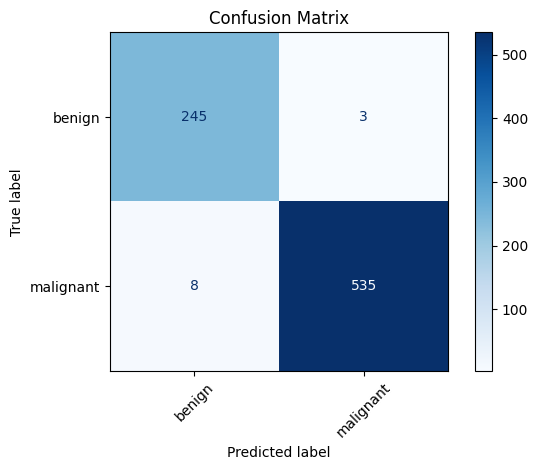

Test - Loss: 0.2245, Acc: 0.9861, Prec: 0.9814, Recall: 0.9866, F1: 0.9839
✅ Correct Predictions: 780/791 (98.61%)


In [19]:
# ============================================================
# FINAL RUN BLOCK (UNCERTAINTY-AWARE)
# ============================================================

class_names = ['benign', 'malignant']

# ============================================================
# DEVICE
# ============================================================

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = model.to(device)

print("Using device:", device)

# ============================================================
# OPTIMIZER
# ------------------------------------------------------------
# AdamW improves generalization and stability
# ============================================================

FOUND_LR = 3e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=FOUND_LR,
    weight_decay=1e-4
)

# ============================================================
# COSINE ANNEALING LR SCHEDULER
# ============================================================

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=100,
    eta_min=1e-6
)

# ============================================================
# START TRAINING
# ============================================================

history = run_training(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    optimizer=optimizer,
    scheduler=scheduler,
    device=device,
    class_names=class_names,
    num_epochs=100
)

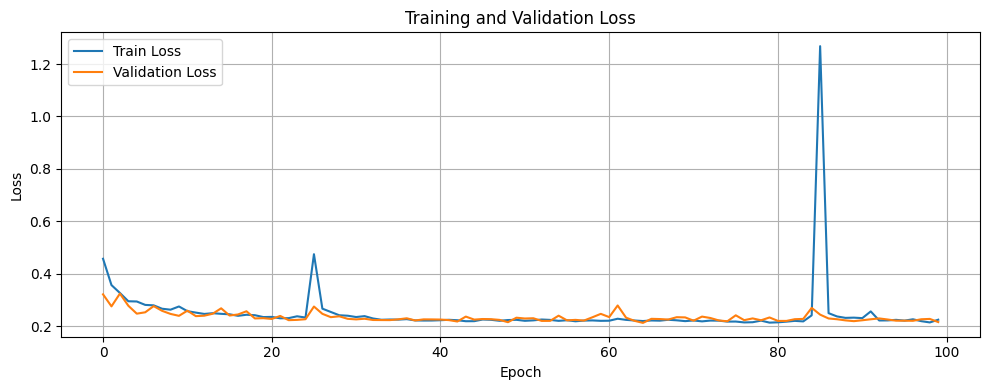

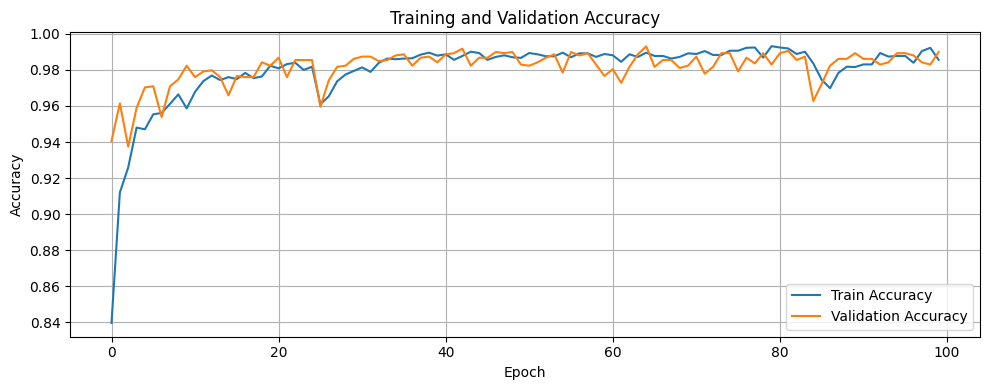

In [20]:
# ============================================================
# TRAINING & VALIDATION CURVES
# ============================================================

import matplotlib.pyplot as plt

# ============================================================
# LOSS CURVE
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(history["train_loss"], label='Train Loss')
plt.plot(history["val_loss"], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# ACCURACY CURVE
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(history["train_acc"], label='Train Accuracy')
plt.plot(history["val_acc"], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# BLOCK 14: FEATURE EXTRACTION FOR t-SNE VISUALIZATION
# ------------------------------------------------------------
# PURPOSE:
# Extract the final discriminative feature embedding learned
# by the proposed Hybrid Network before classification.
#
# Feature Extraction Pipeline
#
# Input Image
#      │
#      ▼
# ResNet50 + Modified CBAM
#      │
#      ▼
# MobileNetV2 + Modified CBAM
#      │
#      ▼
# Feature Alignment
#      │
#      ▼
# Tokenization
#      │
#      ▼
# Uncertainty Estimation
#      │
#      ▼
# Bidirectional Cross Attention
#      │
#      ▼
# Uncertainty-Guided Gated Fusion
#      │
#      ▼
# Attention Pooling
#      │
#      ▼
# Final 512-D Embedding
#
# NOTE:
# This block reproduces the forward pipeline ONLY up to the
# embedding stage used by the classifier.
# The original architecture remains completely unchanged.
# ============================================================

import numpy as np
import torch
from tqdm import tqdm


def extract_features(model, loader, device):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader,
                                   desc="Extracting Features"):

            images = images.to(device)

            # --------------------------------------------------
            # Backbone Feature Extraction
            # --------------------------------------------------

            fr = model.resnet(images)

            fm = model.mobilenet(images)

            # --------------------------------------------------
            # Feature Alignment
            # --------------------------------------------------

            fr, fm = model.align(fr, fm)

            # --------------------------------------------------
            # Convert Feature Maps into Tokens
            # --------------------------------------------------

            B, C, H, W = fr.shape

            fr = fr.reshape(B, C, -1).permute(0, 2, 1)

            fm = fm.reshape(B, C, -1).permute(0, 2, 1)

            # --------------------------------------------------
            # Uncertainty Estimation
            # --------------------------------------------------

            sigma_r = model.uncertainty_r(fr)

            sigma_m = model.uncertainty_m(fm)

            # --------------------------------------------------
            # Bidirectional Cross Attention
            # --------------------------------------------------

            fr_cross = model.cross_attn(
                fr,
                fm,
                sigma_m
            )

            fm_cross = model.cross_attn(
                fm,
                fr,
                sigma_r
            )

            # --------------------------------------------------
            # Uncertainty-Guided Fusion
            # --------------------------------------------------

            fused_tokens = model.fusion(
                fr_cross,
                fm_cross,
                sigma_r,
                sigma_m
            )

            # --------------------------------------------------
            # Attention Pooling
            # --------------------------------------------------

            attention_scores = model.attention_pool(
                fused_tokens
            )

            attention_weights = torch.softmax(
                attention_scores,
                dim=1
            )

            fused_embedding = torch.sum(
                attention_weights * fused_tokens,
                dim=1
            )

            # --------------------------------------------------
            # Store Features
            # --------------------------------------------------

            features.append(
                fused_embedding.cpu().numpy()
            )

            labels_list.extend(
                labels.cpu().numpy()
            )

    features = np.concatenate(features, axis=0)

    labels_list = np.array(labels_list)

    return features, labels_list

In [22]:
# ============================================================
# BLOCK 15: COMPUTE t-SNE EMBEDDINGS
# ------------------------------------------------------------
# Computes a 2-dimensional embedding of the extracted
# 512-dimensional feature vectors for visualization.
# ============================================================

from sklearn.manifold import TSNE

# ------------------------------------------------------------
# Extract Final Feature Embeddings
# ------------------------------------------------------------

features, labels = extract_features(
    model,
    test_loader,
    device
)

# ------------------------------------------------------------
# t-SNE Projection
# ------------------------------------------------------------

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

features_tsne = tsne.fit_transform(features)

Extracting Features: 100%|██████████| 50/50 [00:05<00:00,  9.55it/s]


In [23]:
# ============================================================
# BLOCK 16: t-SNE VISUALIZATION
# ------------------------------------------------------------
# Visualizes the learned feature space of the proposed
# Hybrid Network using t-SNE.
# ============================================================

import matplotlib.pyplot as plt


def plot_tsne(features_tsne,
              labels,
              class_names):

    plt.figure(figsize=(8, 6))

    colors = [
        "royalblue",
        "crimson",
        "forestgreen",
        "darkorange",
        "purple",
        "brown",
        "cyan",
        "olive"
    ]

    unique_labels = np.unique(labels)

    for idx, label in enumerate(unique_labels):

        mask = labels == label

        plt.scatter(
            features_tsne[mask, 0],
            features_tsne[mask, 1],
            s=35,
            alpha=0.8,
            color=colors[idx],
            label=class_names[label]
        )

    plt.title(
        "t-SNE Visualization of Learned Feature Embeddings",
        fontsize=14
    )

    plt.xlabel("t-SNE Dimension 1")

    plt.ylabel("t-SNE Dimension 2")

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.show()

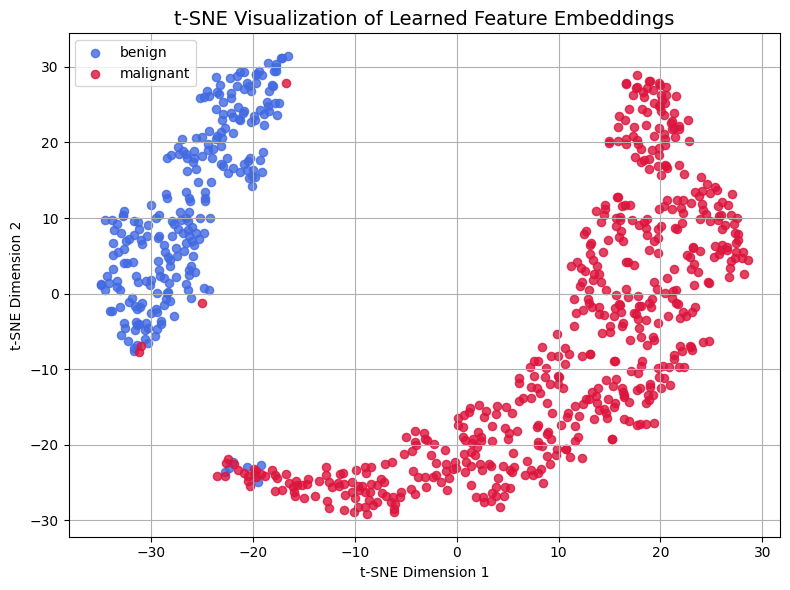

In [24]:
# ============================================================
# BLOCK 17: RUN t-SNE VISUALIZATION
# ============================================================

plot_tsne(
    features_tsne,
    labels,
    class_names
)

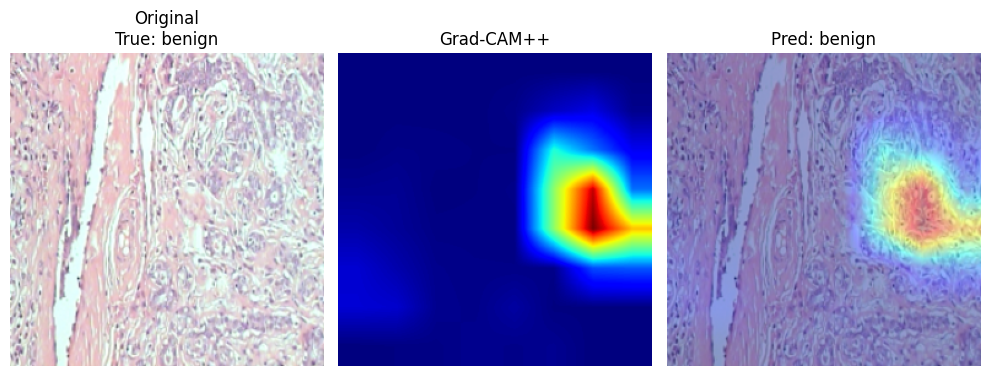

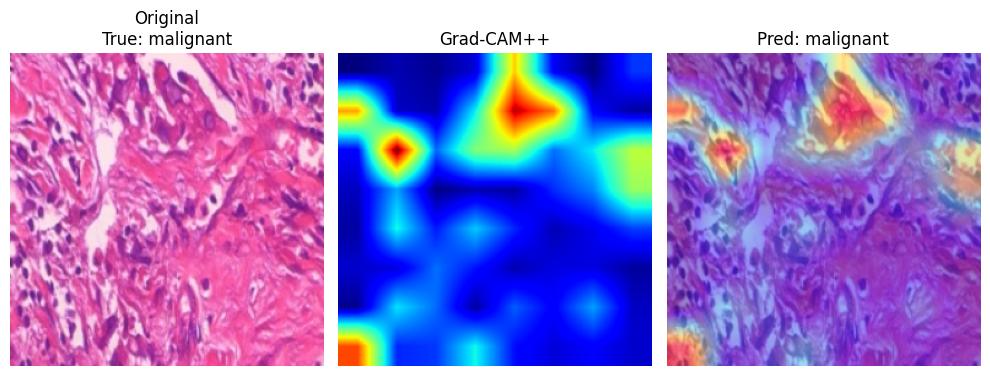

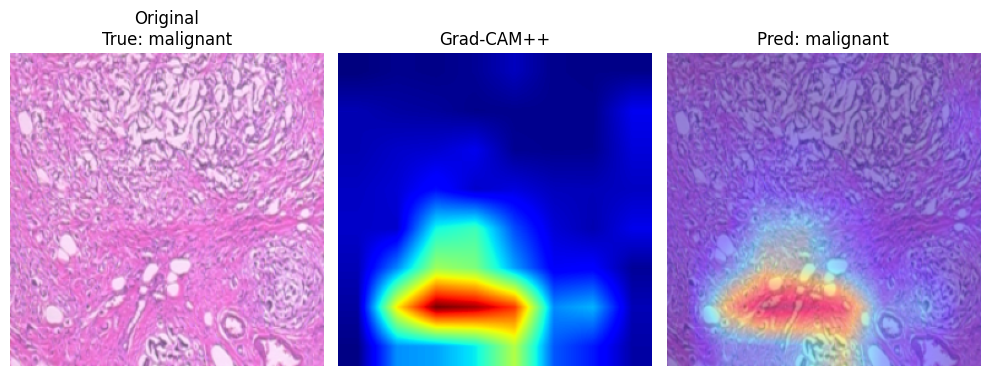

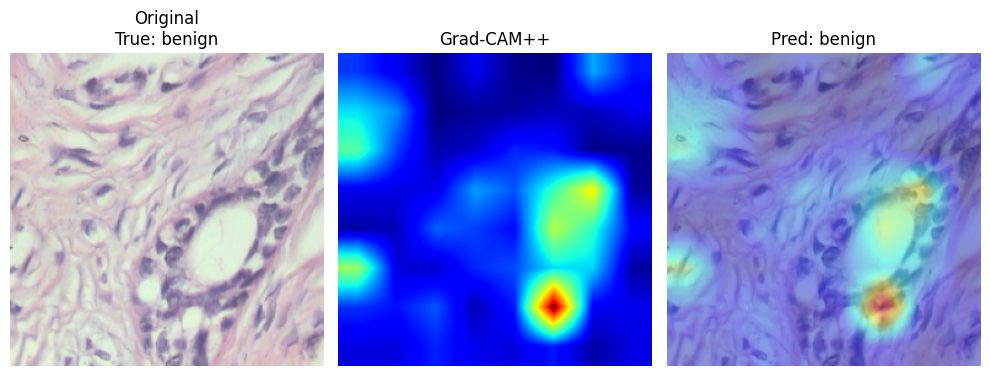

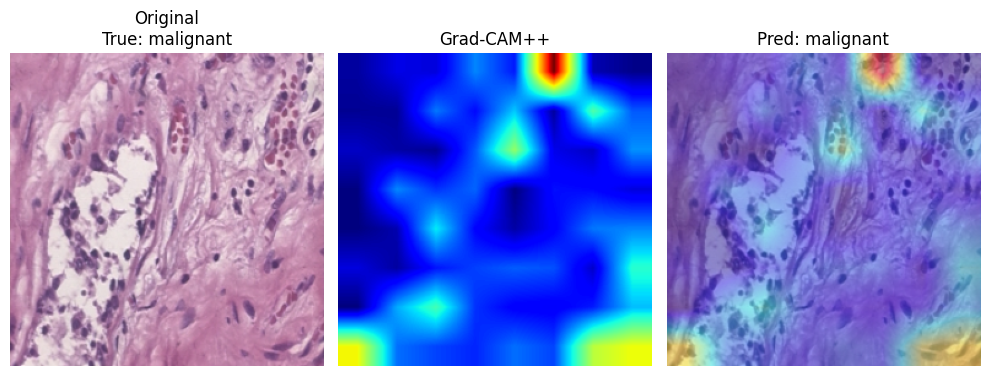

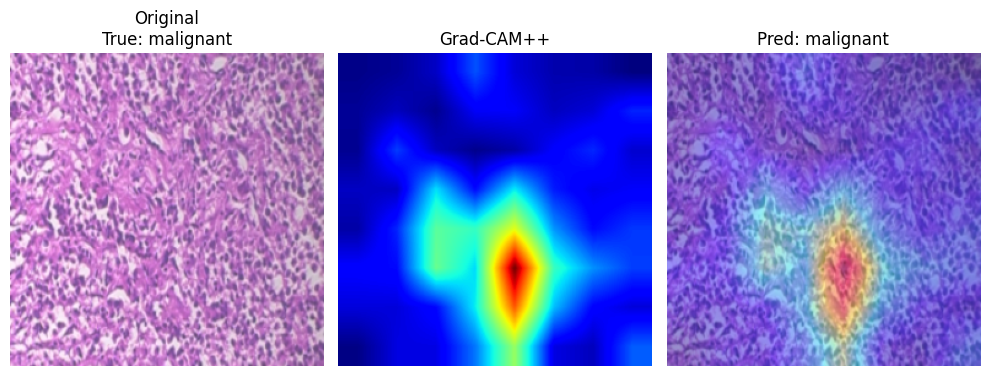

In [25]:
# ============================================
# Grad-CAM++ (UPDATED FOR HYBRID MODEL - BINARY SETUP)
# ============================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2

# -------------------------------
# Grad-CAM++ Class (SAFE HOOKS)
# -------------------------------
class GradCAMPlusPlus:
    def __init__(self, model, target_module):
        self.model = model
        self.target_module = target_module

        self.gradients = None
        self.activations = None

        # Forward hook
        self.target_module.register_forward_hook(self.forward_hook)

        # FULL backward hook (safe)
        self.target_module.register_full_backward_hook(self.backward_hook)

    def forward_hook(self, module, input, output):
        self.activations = output.detach()

    def backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()

        input_tensor = input_tensor.requires_grad_(True)

        # Forward
        output, sigma_r, sigma_m = self.model(input_tensor)

        # If class not specified → use predicted class
        if class_idx is None:
            class_idx = torch.argmax(output, dim=1).item()

        # Backward
        self.model.zero_grad()
        target = output[0, class_idx]
        target.backward(retain_graph=True)

        gradients = self.gradients[0]      # [C,H,W]
        activations = self.activations[0]  # [C,H,W]

        # -------------------------------
        # Grad-CAM++ weights
        # -------------------------------
        grad_2 = gradients ** 2
        grad_3 = gradients ** 3

        eps = 1e-8
        denominator = 2 * grad_2 + torch.sum(
            activations * grad_3, dim=(1, 2), keepdim=True
        )

        denominator = torch.where(denominator != 0.0, denominator, eps)

        alpha = grad_2 / denominator
        weights = torch.sum(alpha * F.relu(gradients), dim=(1, 2))

        # -------------------------------
        # CAM
        # -------------------------------
        cam = torch.sum(weights.view(-1, 1, 1) * activations, dim=0)

        cam = F.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam.cpu().numpy(), class_idx


# -------------------------------
# Visualization (MULTI-CLASS SAFE)
# -------------------------------
def visualize_gradcam(model, loader, device, class_names, num_images=6):
    model.eval()

    target_layer = model.resnet.cbam
    gradcam = GradCAMPlusPlus(model, target_layer)

    images_shown = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        for i in range(images.size(0)):
            if images_shown >= num_images:
                return

            img_tensor = images[i].unsqueeze(0)

            cam, pred_class = gradcam.generate(img_tensor)

            true_class = labels[i].item()

            # -------------------------------
            # Convert tensor → image
            # -------------------------------
            img = images[i].cpu().permute(1, 2, 0).numpy()

            mean = np.array([0.485, 0.456, 0.406])
            std  = np.array([0.229, 0.224, 0.225])
            img = std * img + mean
            img = np.clip(img, 0, 1)

            # -------------------------------
            # Resize CAM
            # -------------------------------
            cam = cv2.resize(cam, (img.shape[1], img.shape[0]))

            heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
            heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0

            overlay = 0.6 * img + 0.4 * heatmap
            overlay = np.clip(overlay, 0, 1)

            # -------------------------------
            # Plot
            # -------------------------------
            plt.figure(figsize=(10,4))

            plt.subplot(1,3,1)
            plt.imshow(img)
            plt.title(f"Original\nTrue: {class_names[true_class]}")
            plt.axis("off")

            plt.subplot(1,3,2)
            plt.imshow(cam, cmap='jet')
            plt.title("Grad-CAM++")
            plt.axis("off")

            plt.subplot(1,3,3)
            plt.imshow(overlay)
            plt.title(f"Pred: {class_names[pred_class]}")
            plt.axis("off")

            plt.tight_layout()
            plt.show()

            images_shown += 1


# -------------------------------
# RUN (SAFE)
# -------------------------------
visualize_gradcam(
    model=model,
    loader=test_loader,
    device=device,
    class_names=class_names,
    num_images=6
)

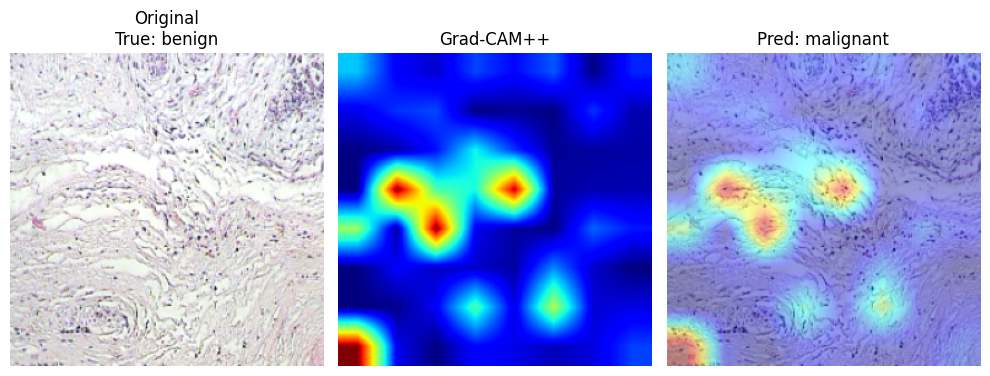

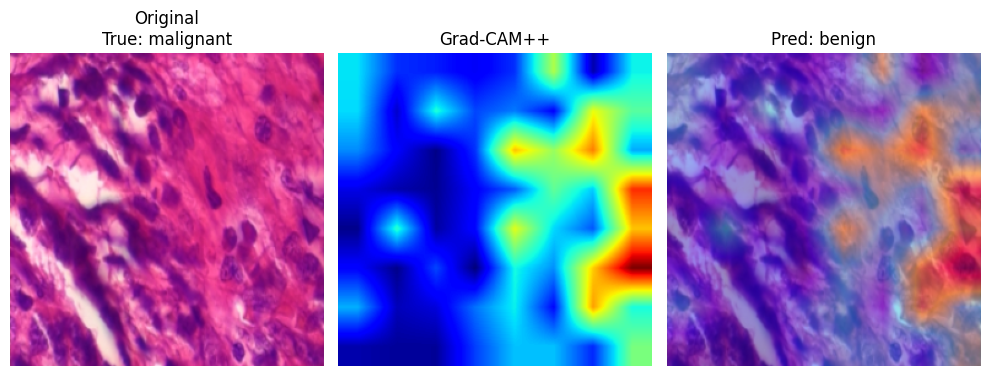

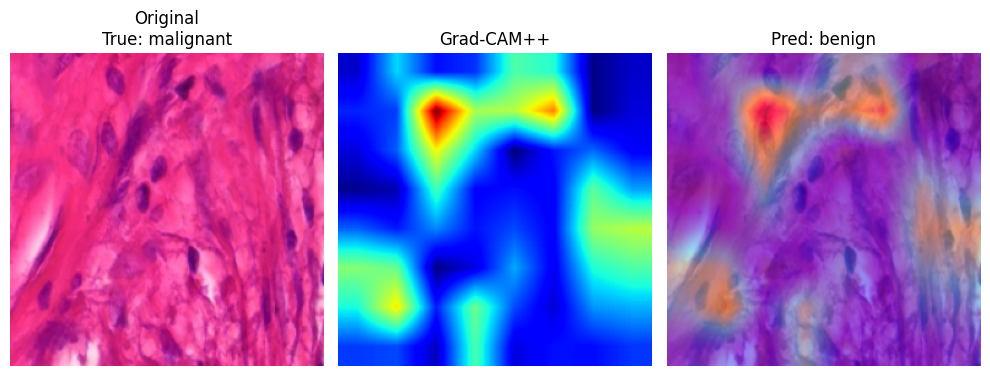

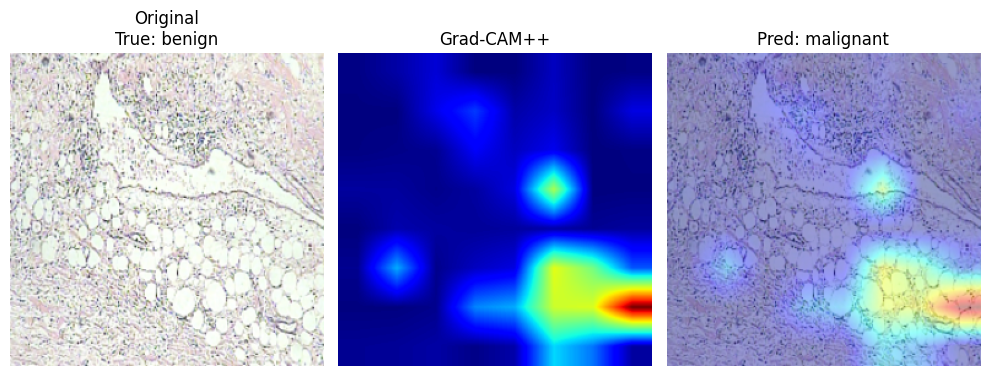

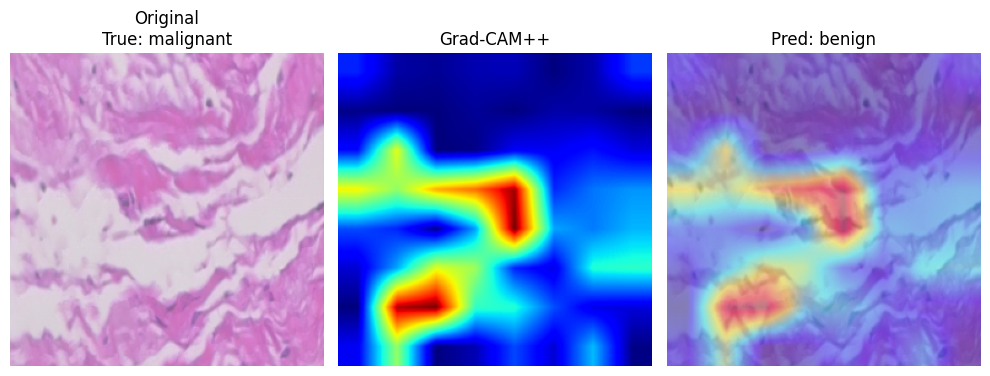

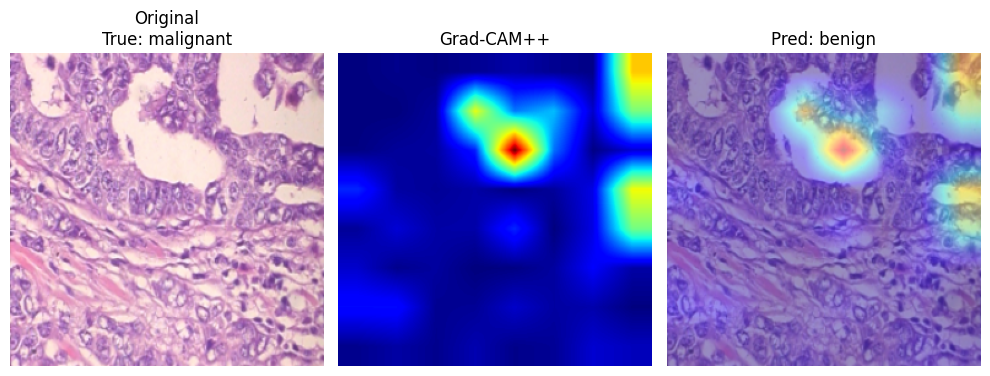

In [26]:

# ============================================
# Grad-CAM++ FOR MISCLASSIFIED SAMPLES - BREAKHIS
# ============================================

def visualize_misclassified_gradcam(model, loader, device, class_names, num_images=6):
    model.eval()

    target_layer = model.resnet.cbam
    gradcam = GradCAMPlusPlus(model, target_layer)

    images_shown = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        for i in range(images.size(0)):
            if images_shown >= num_images:
                return

            img_tensor = images[i].unsqueeze(0)

            cam, pred_class = gradcam.generate(img_tensor)

            true_class = labels[i].item()

            # -------------------------------
            # Misclassified samples only
            # -------------------------------
            if pred_class == true_class:
                continue

            # -------------------------------
            # Convert tensor → image
            # -------------------------------
            img = images[i].cpu().permute(1, 2, 0).numpy()

            mean = np.array([0.485, 0.456, 0.406])
            std  = np.array([0.229, 0.224, 0.225])
            img = std * img + mean
            img = np.clip(img, 0, 1)

            # -------------------------------
            # Resize CAM
            # -------------------------------
            cam = cv2.resize(cam, (img.shape[1], img.shape[0]))

            heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
            heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0

            overlay = 0.6 * img + 0.4 * heatmap
            overlay = np.clip(overlay, 0, 1)

            # -------------------------------
            # Plot
            # -------------------------------
            plt.figure(figsize=(10,4))

            plt.subplot(1,3,1)
            plt.imshow(img)
            plt.title(f"Original\nTrue: {class_names[true_class]}")
            plt.axis("off")

            plt.subplot(1,3,2)
            plt.imshow(cam, cmap='jet')
            plt.title("Grad-CAM++")
            plt.axis("off")

            plt.subplot(1,3,3)
            plt.imshow(overlay)
            plt.title(f"Pred: {class_names[pred_class]}")
            plt.axis("off")

            plt.tight_layout()
            plt.show()

            images_shown += 1

    if images_shown == 0:
        print("No misclassified samples found in the test loader.")
    elif images_shown < num_images:
        print(f"Only {images_shown} misclassified samples found.")

# -------------------------------
# RUN (SAFE)
# -------------------------------
visualize_misclassified_gradcam(
    model=model,
    loader=test_loader,
    device=device,
    class_names=class_names,
    num_images=6
)
